# Week 5: Data Cleaning and Preprocessing
**LAG-CPE 313 Data Science Fundamentals** · University of Lagos · Department of Electrical and Electronic Engineering

Field data is messy. Sensors drop out, people type the same crop three different ways, and loggers write error codes as numbers. Cleaning is usually most of the work in a real project.

### By the end of this notebook you will be able to
- Find and handle missing values and duplicates
- Standardise inconsistent text, dates and units
- Detect outliers with the IQR rule and z-scores
- Validate data with explicit checks
- Transform, scale and encode variables for analysis

### Reading
- [Python for Data Analysis, Ch. 7: Data cleaning and preparation](https://wesmckinney.com/book/data-cleaning.html)
- [Python Data Science Handbook, 3.4: Handling missing data](https://jakevdp.github.io/PythonDataScienceHandbook/03.04-missing-values.html)
- [Chicago Guide, Ch. 6.1–6.2](https://ds1.datascience.uchicago.edu/07/1/Functions_to_DataFrames.html)

> **How to use this notebook.** Run each code cell in order with **Shift + Enter**. Cells marked **✏️ Try it** are for you to complete. Click **Show solution** only after you have tried.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (8, 4)
pd.set_option("display.precision", 3)

## 1. A messy dataset
This is a log from several plots, typed partly by hand and partly by sensors.

In [3]:
messy = pd.DataFrame({
    "date": ["2025-03-01", "02/03/2025", "2025-03-03", "2025-03-03", "2025-03-04", "2025-03-05", "2025-03-06", "2025-03-07"],
    "plot": ["P1", "P1", "P2", "P2", "p3 ", "P3", "P1", "P2"],
    "crop": ["Maize", "maize ", "MAIZE", "MAIZE", "Cassava", "cassava", "Maize", "maize"],
    "soil_moisture": [0.21, None, 0.19, 0.19, -999, 0.17, 0.22, 0.95],
    "temp": ["29.1 C", "30.2C", "28.7 C", "28.7 C", "31.0 C", None, "29.8 C", "30.5 C"],
    "pump_kwh": [1.2, 1.5, 0.0, 0.0, 2.1, 1.8, 1.1, 1.3],
})
messy

,date,plot,crop,soil_moisture,temp,pump_kwh
0,2025-03-01,P1,Maize,0.21,29.1 C,1.2
1,02/03/2025,P1,maize,NaN,30.2C,1.5
2,2025-03-03,P2,MAIZE,0.19,28.7 C,0.0
3,2025-03-03,P2,MAIZE,0.19,28.7 C,0.0
4,2025-03-04,p3,Cassava,-999.00,31.0 C,2.1
5,2025-03-05,P3,cassava,0.17,None,1.8
6,2025-03-06,P1,Maize,0.22,29.8 C,1.1
7,2025-03-07,P2,maize,0.95,30.5 C,1.3


Spot the problems: mixed date formats, inconsistent plot and crop labels, a missing value, a `-999` error code, a moisture of 0.95 (physically implausible for this soil), units inside the temperature text, and a duplicated row.

## 2. Duplicates

In [4]:
print("Duplicate rows:", messy.duplicated().sum())
clean = messy.drop_duplicates().reset_index(drop=True)

Duplicate rows: 1


## 3. Inconsistent text

In [5]:
clean["plot"] = clean["plot"].str.strip().str.upper()
clean["crop"] = clean["crop"].str.strip().str.title()
clean[["plot", "crop"]].value_counts()

,,count
plot,crop,
P1,Maize,3
P2,Maize,2
P3,Cassava,2


## 4. Dates and units

In [6]:
# Nigerian records usually write dates day-first (02/03/2025 = 2 March), so parse each format explicitly
iso = pd.to_datetime(clean["date"], format="%Y-%m-%d", errors="coerce")
dmy = pd.to_datetime(clean["date"], format="%d/%m/%Y", errors="coerce")
clean["date"] = iso.fillna(dmy)
clean["temp_c"] = clean["temp"].str.replace("C", "").str.strip().astype(float)
clean = clean.drop(columns="temp")
clean.dtypes

,0
date,datetime64[ns]
plot,object
crop,object
soil_moisture,float64
pump_kwh,float64
temp_c,float64


## 5. Error codes and impossible values
Turn sentinel values like `-999` into missing values, and flag values outside the physically possible range.

In [7]:
clean["soil_moisture"] = clean["soil_moisture"].replace(-999, np.nan)
implausible = (clean["soil_moisture"] < 0.05) | (clean["soil_moisture"] > 0.50)
print("Implausible readings:\n", clean.loc[implausible, ["date", "plot", "soil_moisture"]])
clean.loc[implausible, "soil_moisture"] = np.nan

Implausible readings:
         date plot  soil_moisture
6 2025-03-07   P2           0.95


## 6. Missing values
Options: **drop** rows, **fill** with a constant or a statistic, or **interpolate** along time. The right choice depends on why the value is missing.

In [8]:
print(clean.isna().sum())
filled = clean.copy()
filled["temp_c"] = filled["temp_c"].fillna(filled["temp_c"].median())
filled = filled.sort_values(["plot", "date"])
filled["soil_moisture"] = filled.groupby("plot")["soil_moisture"].transform(lambda s: s.interpolate().bfill().ffill())
filled

date             0
plot             0
crop             0
soil_moisture    3
pump_kwh         0
temp_c           1
dtype: int64


,date,plot,crop,soil_moisture,pump_kwh,temp_c
0,2025-03-01,P1,Maize,0.210,1.2,29.1
1,2025-03-02,P1,Maize,0.215,1.5,30.2
5,2025-03-06,P1,Maize,0.220,1.1,29.8
2,2025-03-03,P2,Maize,0.190,0.0,28.7
6,2025-03-07,P2,Maize,0.190,1.3,30.5
3,2025-03-04,P3,Cassava,0.170,2.1,31.0
4,2025-03-05,P3,Cassava,0.170,1.8,30.0


## 7. Outliers in a larger dataset
We add a few faulty spikes to the farm’s pump data and find them.

In [10]:
def make_farm_data(days=365, seed=42):
    """Synthetic daily data for a smallholder farm with a solar irrigation pump
    in south-west Nigeria (rainy season roughly April to October)."""
    rng = np.random.default_rng(seed)
    dates = pd.date_range("2025-01-01", periods=days, freq="D")
    doy = dates.dayofyear.values
    wet = ((doy >= 95) & (doy <= 300)).astype(float)
    temp = 27 + 2.5 * np.cos(2 * np.pi * (doy - 60) / 365) - 1.2 * wet + rng.normal(0, 1.0, days)
    rain = rng.gamma(0.7, 14, days) * (rng.random(days) < (0.08 + 0.47 * wet))
    solar = np.clip(5.9 - 1.3 * wet - 0.02 * rain + rng.normal(0, 0.5, days), 1.5, 7.5)
    soil = np.zeros(days); irr = np.zeros(days); soil[0] = 0.24
    for t in range(1, days):
        loss = 0.0035 * (temp[t] - 18) + 0.002 * solar[t]
        irr[t] = rng.uniform(8, 14) if soil[t - 1] < 0.18 else 0.0
        soil[t] = np.clip(soil[t - 1] - loss + 0.004 * rain[t] + 0.004 * irr[t], 0.06, 0.45)
    pump_kwh = np.clip(irr * 0.16 + rng.normal(0, 0.08, days), 0, None) * (irr > 0)
    return pd.DataFrame({
        "date": dates,
        "temp_c": temp.round(1),
        "rain_mm": rain.round(1),
        "solar_kwh_m2": solar.round(2),
        "soil_moisture": soil.round(3),
        "irrigation_mm": irr.round(1),
        "pump_kwh": pump_kwh.round(2),
    })

IQR outliers:
 11     9.50
49    12.00
79     0.01
Name: pump_kwh, dtype: float64 
z-score outliers:
 11     9.5
49    12.0
Name: pump_kwh, dtype: float64


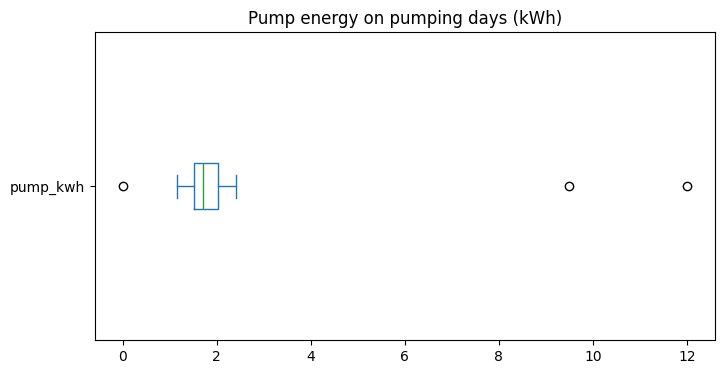

In [11]:
farm = make_farm_data()
pumped = farm.loc[farm.pump_kwh > 0, "pump_kwh"].copy()
pumped.iloc[[5, 40, 70]] = [9.5, 12.0, 0.01]      # injected faults

q1, q3 = pumped.quantile([0.25, 0.75]); iqr = q3 - q1
iqr_out = pumped[(pumped < q1 - 1.5 * iqr) | (pumped > q3 + 1.5 * iqr)]
z = (pumped - pumped.mean()) / pumped.std()
z_out = pumped[z.abs() > 3]
print("IQR outliers:\n", iqr_out, "\nz-score outliers:\n", z_out)
pumped.plot(kind="box", vert=False); plt.title("Pump energy on pumping days (kWh)"); plt.show()

Not every outlier is an error. A very high reading may be a real heatwave. **Check with someone who knows the system before deleting.**

## 8. Validation
Write checks that stop the analysis if the data breaks your assumptions.

In [12]:
def validate(df):
    assert df["soil_moisture"].between(0.05, 0.5).all(), "moisture out of range"
    assert df["pump_kwh"].ge(0).all(), "negative energy"
    assert not df.duplicated().any(), "duplicate rows"
    return "All checks passed"
validate(filled)

'All checks passed'

## 9. Transformations
Rainfall is very skewed: many dry days and a few huge storms. A log transform makes it easier to model.

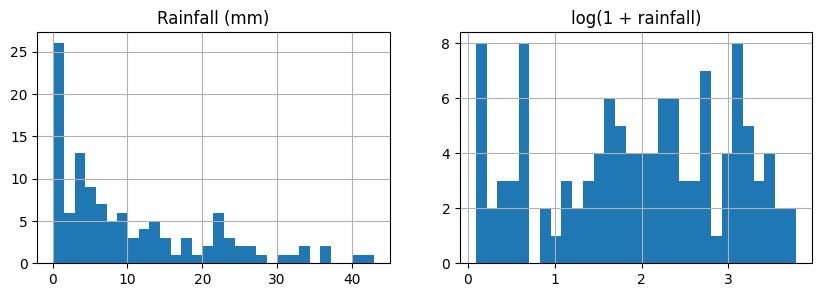

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
rainy = farm.loc[farm.rain_mm > 0, "rain_mm"]
rainy.hist(bins=30, ax=ax[0]); ax[0].set_title("Rainfall (mm)")
np.log1p(rainy).hist(bins=30, ax=ax[1]); ax[1].set_title("log(1 + rainfall)")
plt.show()

## 10. Scaling
Variables measured in different units (°C, mm, kWh) need scaling before methods that compare distances.
- **Min–max normalisation** maps to the range 0–1
- **Standardisation (z-score)** gives mean 0 and standard deviation 1

In [14]:
cols = ["temp_c", "rain_mm", "solar_kwh_m2"]
minmax = (farm[cols] - farm[cols].min()) / (farm[cols].max() - farm[cols].min())
zscore = (farm[cols] - farm[cols].mean()) / farm[cols].std()
pd.concat({"original": farm[cols].describe().loc[["mean", "std", "min", "max"]],
           "min-max": minmax.describe().loc[["mean", "std", "min", "max"]],
           "z-score": zscore.describe().loc[["mean", "std", "min", "max"]]}, axis=1).round(2)

original                      min-max                      z-score  \
       temp_c rain_mm solar_kwh_m2  temp_c rain_mm solar_kwh_m2  temp_c   
mean    26.32    3.31         5.04    0.51    0.08         0.49   -0.00   
std      2.39    7.61         0.85    0.24    0.18         0.19    1.00   
min     21.20    0.00         2.81    0.00    0.00         0.00   -2.14   
max     31.30   42.90         7.36    1.00    1.00         1.00    2.08   

                           
     rain_mm solar_kwh_m2  
mean    0.00        -0.00  
std     1.00         1.00  
min    -0.44        -2.62  
max     5.21         2.73

## 11. Encoding categorical variables
Models need numbers. **One-hot encoding** creates a 0/1 column per category; **ordinal encoding** is for categories with a natural order.

In [ ]:
plots = pd.DataFrame({"soil_type": ["loam", "sandy", "clay", "loam"],
                      "irrigation": ["none", "rainfed+pump", "drip", "drip"],
                      "stress_level": ["low", "high", "medium", "low"]})
onehot = pd.get_dummies(plots, columns=["soil_type", "irrigation"], dtype=int)
onehot["stress_level"] = plots["stress_level"].map({"low": 0, "medium": 1, "high": 2})
onehot

### ✏️ Try it 1
Clean this column of yields typed by enumerators: strip text, convert to float in t/ha (values in kg/ha must be divided by 1000), and replace `'n/a'` with a missing value.

In [ ]:
yields = pd.Series(["3.2 t/ha", "2950 kg/ha", "n/a", " 4.1 t/ha", "3100 kg/ha"])

<details><summary><b>Show solution</b></summary>

```python
def to_t_ha(s):
    s = s.strip().lower()
    if s == "n/a": return np.nan
    value, unit = s.split()
    return float(value) / 1000 if unit == "kg/ha" else float(value)
yields.apply(to_t_ha)
```
</details>

### ✏️ Try it 2
In `farm`, standardise `pump_kwh` and list the days with |z| > 2.5.

<details><summary><b>Show solution</b></summary>

```python
z = (farm.pump_kwh - farm.pump_kwh.mean()) / farm.pump_kwh.std()
farm.loc[z.abs() > 2.5, ["date", "pump_kwh"]]
```
</details>

### 🧑🏾‍🌾 Human in the loop
Your outlier check flagged a very high pump reading on one day. Write down the question you would ask the farm technician before deciding whether to keep, fix or delete it.

## Summary
- Fix duplicates, labels, dates and units first
- Treat error codes and impossible values as missing
- Choose drop, fill or interpolate based on why data is missing
- Check outliers with domain experts before removing them
- Scale numeric features and encode categories before modelling

**Next week:** describing data with summary statistics.